In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

csv_path = '/content/drive/MyDrive/skin-cancer-fusion/data_ndb_ufes/ndb-ufes.csv'
df = pd.read_csv(csv_path)

print("Total rows:", len(df))
print("\nAll columns:")
print(df.columns.tolist())

print("\nMissing values per column:")
print(df.isnull().sum())

df.head()

Mounted at /content/drive
Total rows: 237

All columns:
['public_id', 'lesion_id', 'patient_id', 'path', 'localization', 'larger_size', 'tobacco_use', 'alcohol_consumption', 'sun_exposure', 'gender', 'skin_color', 'age_group', 'diagnosis', 'dysplasia_severity', 'TaskII', 'TaskIII', 'TaskIV']

Missing values per column:
public_id                0
lesion_id                0
patient_id               0
path                     0
localization             0
larger_size              0
tobacco_use              0
alcohol_consumption      0
sun_exposure             0
gender                   0
skin_color               0
age_group                0
diagnosis                0
dysplasia_severity     148
TaskII                   0
TaskIII                  0
TaskIV                   0
dtype: int64


,public_id,lesion_id,patient_id,path,localization,larger_size,tobacco_use,alcohol_consumption,sun_exposure,gender,skin_color,age_group,diagnosis,dysplasia_severity,TaskII,TaskIII,TaskIV
0,0,50,48,0000.png,Tongue,2.0,Yes,No,No,M,Black,2,OSCC,NaN,OSCC,Presence,OSCC
1,1,50,48,0001.png,Tongue,2.0,Yes,No,No,M,Black,2,OSCC,NaN,OSCC,Presence,OSCC
2,2,41,39,0002.png,Tongue,2.5,Yes,Former,Yes,M,White,1,OSCC,NaN,OSCC,Presence,OSCC
3,3,41,39,0003.png,Tongue,2.5,Yes,Former,Yes,M,White,1,OSCC,NaN,OSCC,Presence,OSCC
4,4,87,81,0004.png,Lip,1.5,Former,Yes,Yes,F,White,2,OSCC,NaN,OSCC,Presence,OSCC


In [2]:
print("Diagnosis distribution:")
print(df['diagnosis'].value_counts())

print("\nDysplasia severity distribution (where present):")
print(df['dysplasia_severity'].value_counts())

Diagnosis distribution:
diagnosis
OSCC                             91
Leukoplakia with dysplasia       89
Leukoplakia without dysplasia    57
Name: count, dtype: int64

Dysplasia severity distribution (where present):
dysplasia_severity
Mild        58
Severe      16
Moderate    15
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np

def encode_metadata(df, cat_cols, numeric_cols, reference_columns=None):
    df_cat = pd.get_dummies(df[cat_cols].astype(str))
    df_num = df[numeric_cols].fillna(df[numeric_cols].median())
    df_encoded = pd.concat([df_num, df_cat], axis=1)
    if reference_columns is not None:
        df_encoded = df_encoded.reindex(columns=reference_columns, fill_value=0)
    return df_encoded

In [5]:
cat_cols = ['localization', 'tobacco_use', 'alcohol_consumption', 'sun_exposure', 'gender', 'skin_color']
numeric_cols = ['larger_size', 'age_group']

train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df['diagnosis'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['diagnosis'], random_state=42)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))

train_meta = encode_metadata(train_df, cat_cols, numeric_cols)
val_meta = encode_metadata(val_df, cat_cols, numeric_cols, reference_columns=train_meta.columns)
test_meta = encode_metadata(test_df, cat_cols, numeric_cols, reference_columns=train_meta.columns)

print("Feature count:", train_meta.shape[1])

Train: 165 Val: 36 Test: 36
Feature count: 25


In [6]:
le_ndb = LabelEncoder()
le_ndb.fit(train_df['diagnosis'])

train_labels = le_ndb.transform(train_df['diagnosis'])
val_labels = le_ndb.transform(val_df['diagnosis'])
test_labels = le_ndb.transform(test_df['diagnosis'])

print("Classes:", le_ndb.classes_)

Classes: ['Leukoplakia with dysplasia' 'Leukoplakia without dysplasia' 'OSCC']


In [7]:
train_df = train_df.rename(columns={'path': 'img_id', 'diagnosis': 'diagnostic'})
val_df = val_df.rename(columns={'path': 'img_id', 'diagnosis': 'diagnostic'})
test_df = test_df.rename(columns={'path': 'img_id', 'diagnosis': 'diagnostic'})

In [8]:
import zipfile, os

zip_path = '/content/drive/MyDrive/skin-cancer-fusion/data_ndb_ufes/images.zip'
extract_path = '/content/ndb_images'
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Contents:", os.listdir(extract_path)[:5])
print("Total items:", len(os.listdir(extract_path)))

Contents: ['images']
Total items: 1


In [9]:
inner_path = '/content/ndb_images/images'
contents = os.listdir(inner_path)
print("First 5 items:", contents[:5])
print("Total items:", len(contents))

First 5 items: ['0102.png', '0077.png', '0193.png', '0187.png', '0230.png']
Total items: 237


In [12]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
import torch.nn as nn
import torchvision.models as models

class SkinFusionDataset(Dataset):
    def __init__(self, df, meta_features, labels, image_folders, transform=None):
        self.df = df.reset_index(drop=True)
        self.meta_features = meta_features.reset_index(drop=True)
        self.labels = labels
        self.image_folders = image_folders
        self.transform = transform
        self.image_lookup = {}
        for folder in image_folders:
            for fname in os.listdir(folder):
                self.image_lookup[fname] = os.path.join(folder, fname)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'img_id']
        img_path = self.image_lookup[img_name]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        meta = torch.tensor(self.meta_features.iloc[idx].values.astype('float32'))
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, meta, label

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [13]:
image_folders_ndb = ['/content/ndb_images/images']

train_dataset_ndb = SkinFusionDataset(train_df, train_meta, train_labels, image_folders_ndb, train_transform)
val_dataset_ndb = SkinFusionDataset(val_df, val_meta, val_labels, image_folders_ndb, transform)
test_dataset_ndb = SkinFusionDataset(test_df, test_meta, test_labels, image_folders_ndb, transform)

# Test one sample
image, meta, label = train_dataset_ndb[0]
print("Image shape:", image.shape)
print("Meta shape:", meta.shape)
print("Label:", label)

Image shape: torch.Size([3, 224, 224])
Meta shape: torch.Size([25])
Label: tensor(2)


In [14]:
batch_size = 16  # smaller batch since dataset is much smaller (165 train samples)

train_loader_ndb = DataLoader(train_dataset_ndb, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader_ndb = DataLoader(val_dataset_ndb, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader_ndb = DataLoader(test_dataset_ndb, batch_size=batch_size, shuffle=False, num_workers=2)

images, metas, labels = next(iter(train_loader_ndb))
print("Batch shapes:", images.shape, metas.shape, labels.shape)

Batch shapes: torch.Size([16, 3, 224, 224]) torch.Size([16, 25]) torch.Size([16])


In [16]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

class FusionModel(nn.Module):
    def __init__(self, meta_input_dim, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer4' not in name:
                param.requires_grad = False
        self.meta_branch = nn.Sequential(
            nn.Linear(meta_input_dim, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU()
        )
        self.classifier = nn.Sequential(
            nn.Linear(512 + 32, 64), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(64, num_classes)
        )

    def forward(self, image, meta):
        img_feat = self.image_branch(image).flatten(1)
        meta_feat = self.meta_branch(meta)
        combined = torch.cat([img_feat, meta_feat], dim=1)
        return self.classifier(combined)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, metas, labels in loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images, metas)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), correct / total

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            outputs = model(images, metas)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / len(loader), correct / total

Using device: cpu


In [18]:
from sklearn.utils.class_weight import compute_class_weight

In [19]:
model_ndb = FusionModel(meta_input_dim=25, num_classes=3).to(device)
optimizer_ndb = torch.optim.Adam(filter(lambda p: p.requires_grad, model_ndb.parameters()), lr=1e-4, weight_decay=1e-4)

class_weights_ndb = torch.tensor(
    compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels),
    dtype=torch.float32
)
criterion_ndb = nn.CrossEntropyLoss(weight=class_weights_ndb)

print("Model ready")

Model ready


In [20]:
best_val_acc = 0
num_epochs = 8

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model_ndb, train_loader_ndb, criterion_ndb, optimizer_ndb, device)
    val_loss, val_acc = evaluate(model_ndb, val_loader_ndb, criterion_ndb, device)
    print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model_ndb.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_model_ndb.pth')
        print("  -> Saved new best model")

Epoch 1/8 - Train loss: 1.1426, Train acc: 0.3030 - Val loss: 1.0940, Val acc: 0.1944
  -> Saved new best model
Epoch 2/8 - Train loss: 1.0680, Train acc: 0.3697 - Val loss: 1.0974, Val acc: 0.1944
Epoch 3/8 - Train loss: 1.0753, Train acc: 0.3576 - Val loss: 1.0944, Val acc: 0.3056
  -> Saved new best model
Epoch 4/8 - Train loss: 1.0607, Train acc: 0.4364 - Val loss: 1.0824, Val acc: 0.2500
Epoch 5/8 - Train loss: 1.0631, Train acc: 0.4485 - Val loss: 1.0619, Val acc: 0.3611
  -> Saved new best model
Epoch 6/8 - Train loss: 1.0548, Train acc: 0.4121 - Val loss: 1.0600, Val acc: 0.3333
Epoch 7/8 - Train loss: 1.0474, Train acc: 0.4788 - Val loss: 1.0518, Val acc: 0.2500
Epoch 8/8 - Train loss: 1.0421, Train acc: 0.4242 - Val loss: 1.0462, Val acc: 0.5000
  -> Saved new best model


In [21]:
for epoch in range(8):
    train_loss, train_acc = train_one_epoch(model_ndb, train_loader_ndb, criterion_ndb, optimizer_ndb, device)
    val_loss, val_acc = evaluate(model_ndb, val_loader_ndb, criterion_ndb, device)
    print(f"Epoch {epoch+1}/8 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model_ndb.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_model_ndb.pth')
        print("  -> Saved new best model")

Epoch 1/8 - Train loss: 1.0124, Train acc: 0.5455 - Val loss: 1.0428, Val acc: 0.5556
  -> Saved new best model
Epoch 2/8 - Train loss: 1.0263, Train acc: 0.5152 - Val loss: 1.0335, Val acc: 0.3056
Epoch 3/8 - Train loss: 0.9970, Train acc: 0.5394 - Val loss: 1.0271, Val acc: 0.3333
Epoch 4/8 - Train loss: 1.0012, Train acc: 0.5515 - Val loss: 1.0154, Val acc: 0.4722
Epoch 5/8 - Train loss: 0.9945, Train acc: 0.5697 - Val loss: 1.0023, Val acc: 0.5278
Epoch 6/8 - Train loss: 0.9819, Train acc: 0.5394 - Val loss: 1.0047, Val acc: 0.5278
Epoch 7/8 - Train loss: 1.0002, Train acc: 0.5636 - Val loss: 0.9902, Val acc: 0.4722
Epoch 8/8 - Train loss: 0.9462, Train acc: 0.6000 - Val loss: 0.9882, Val acc: 0.5278


In [22]:
model_ndb.load_state_dict(torch.load('/content/drive/MyDrive/skin-cancer-fusion/best_model_ndb.pth'))
test_loss, test_acc = evaluate(model_ndb, test_loader_ndb, criterion_ndb, device)
print(f"NDB-UFES Fusion Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}")

NDB-UFES Fusion Test loss: 1.0528, Test acc: 0.5278


In [23]:
def compute_ablation_importance(model, loader, device):
    model.eval()
    results = {'true_label': [], 'baseline_prob': [], 'no_image_prob': [], 'no_meta_prob': [], 'none_prob': []}
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            baseline_out = torch.softmax(model(images, metas), dim=1)
            zero_images = torch.zeros_like(images)
            no_image_out = torch.softmax(model(zero_images, metas), dim=1)
            zero_metas = torch.zeros_like(metas)
            no_meta_out = torch.softmax(model(images, zero_metas), dim=1)
            none_out = torch.softmax(model(zero_images, zero_metas), dim=1)

            for i in range(labels.size(0)):
                label = labels[i].item()
                results['true_label'].append(label)
                results['baseline_prob'].append(baseline_out[i, label].item())
                results['no_image_prob'].append(no_image_out[i, label].item())
                results['no_meta_prob'].append(no_meta_out[i, label].item())
                results['none_prob'].append(none_out[i, label].item())
    return pd.DataFrame(results)

ablation_df_ndb = compute_ablation_importance(model_ndb, test_loader_ndb, device)
ablation_df_ndb['image_importance'] = ablation_df_ndb['baseline_prob'] - ablation_df_ndb['no_image_prob']
ablation_df_ndb['meta_importance'] = ablation_df_ndb['baseline_prob'] - ablation_df_ndb['no_meta_prob']

ablation_df_ndb['shapley_image'] = 0.5 * (ablation_df_ndb['no_meta_prob'] - ablation_df_ndb['none_prob']) + \
                                     0.5 * (ablation_df_ndb['baseline_prob'] - ablation_df_ndb['no_image_prob'])
ablation_df_ndb['shapley_meta'] = 0.5 * (ablation_df_ndb['no_image_prob'] - ablation_df_ndb['none_prob']) + \
                                    0.5 * (ablation_df_ndb['baseline_prob'] - ablation_df_ndb['no_meta_prob'])

print(ablation_df_ndb[['image_importance', 'meta_importance', 'shapley_image', 'shapley_meta']].describe())

       image_importance  meta_importance  shapley_image  shapley_meta
count         36.000000        36.000000      36.000000     36.000000
mean           0.014162         0.001783       0.013631      0.001252
std            0.060148         0.001895       0.059864      0.001872
min           -0.091970        -0.001135      -0.091335     -0.001134
25%           -0.018747         0.000222      -0.019565     -0.000312
50%           -0.000012         0.001682       0.000318      0.001008
75%            0.057643         0.002795       0.056905      0.002524
max            0.165517         0.006376       0.164269      0.006812


In [24]:
from scipy.stats import spearmanr

corr_image, p_image = spearmanr(ablation_df_ndb['image_importance'], ablation_df_ndb['shapley_image'])
print(f"NDB-UFES Ablation vs Shapley (image): rho={corr_image:.3f}, p={p_image:.4f}")

NDB-UFES Ablation vs Shapley (image): rho=0.999, p=0.0000


In [29]:
!pip install captum -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 14.0 MB/s eta 0:00:00


In [30]:
def compute_ig_importance(model, loader, device):
    model.eval()
    ig_image_scores = []
    ig_meta_scores = []

    def forward_func(images, metas):
        return model(images, metas)

    ig = IntegratedGradients(forward_func)

    for images, metas, labels in loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        images.requires_grad_()
        metas.requires_grad_()
        for i in range(labels.size(0)):
            img_single = images[i:i+1]
            meta_single = metas[i:i+1]
            label = labels[i].item()
            attributions = ig.attribute((img_single, meta_single), target=label, n_steps=20)
            img_attr, meta_attr = attributions
            ig_image_scores.append(img_attr.abs().sum().item())
            ig_meta_scores.append(meta_attr.abs().sum().item())
    return ig_image_scores, ig_meta_scores

from captum.attr import IntegratedGradients

ig_image_ndb, ig_meta_ndb = compute_ig_importance(model_ndb, test_loader_ndb, device)
ablation_df_ndb['ig_image'] = ig_image_ndb

corr_ig, p_ig = spearmanr(ablation_df_ndb['image_importance'], ablation_df_ndb['ig_image'])
print(f"NDB-UFES Ablation vs IG (image): rho={corr_ig:.3f}, p={p_ig:.4f}")

NDB-UFES Ablation vs IG (image): rho=0.120, p=0.4840


In [31]:
def make_truly_random_model(meta_input_dim, num_classes):
    model = FusionModel(meta_input_dim=meta_input_dim, num_classes=num_classes)
    for module in model.image_branch.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    return model.to(device)

random_model_ndb = make_truly_random_model(meta_input_dim=25, num_classes=3)
random_ig_image_ndb, _ = compute_ig_importance(random_model_ndb, test_loader_ndb, device)

corr_sanity, p_sanity = spearmanr(ig_image_ndb, random_ig_image_ndb)
print(f"NDB-UFES Trained-IG vs Random-IG: rho={corr_sanity:.3f}, p={p_sanity:.4f}")

NDB-UFES Trained-IG vs Random-IG: rho=0.504, p=0.0017


In [32]:
class MetaBlock(nn.Module):
    def __init__(self, image_feat_dim, meta_input_dim, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer4' not in name:
                param.requires_grad = False
        self.meta_gate = nn.Sequential(nn.Linear(meta_input_dim, image_feat_dim), nn.Sigmoid())
        self.meta_bias = nn.Sequential(nn.Linear(meta_input_dim, image_feat_dim), nn.Tanh())
        self.classifier = nn.Sequential(
            nn.Linear(image_feat_dim, 64), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(64, num_classes)
        )

    def forward(self, image, meta):
        img_feat = self.image_branch(image).flatten(1)
        gate = self.meta_gate(meta)
        bias = self.meta_bias(meta)
        modulated = img_feat * gate + bias
        return self.classifier(modulated)

metablock_ndb = MetaBlock(image_feat_dim=512, meta_input_dim=25, num_classes=3).to(device)
metablock_optimizer_ndb = torch.optim.Adam(filter(lambda p: p.requires_grad, metablock_ndb.parameters()), lr=1e-4, weight_decay=1e-4)

In [33]:
best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(metablock_ndb, train_loader_ndb, criterion_ndb, metablock_optimizer_ndb, device)
    val_loss, val_acc = evaluate(metablock_ndb, val_loader_ndb, criterion_ndb, device)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(metablock_ndb.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_metablock_ndb.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 1.1019, Train acc: 0.3576 - Val loss: 1.0700, Val acc: 0.4444
  -> Saved new best model
Epoch 2/15 - Train loss: 1.0766, Train acc: 0.4364 - Val loss: 1.0462, Val acc: 0.5278
  -> Saved new best model
Epoch 3/15 - Train loss: 1.0480, Train acc: 0.5030 - Val loss: 1.0266, Val acc: 0.5556
  -> Saved new best model
Epoch 4/15 - Train loss: 1.0250, Train acc: 0.5879 - Val loss: 1.0113, Val acc: 0.5556
Epoch 5/15 - Train loss: 0.9995, Train acc: 0.5818 - Val loss: 0.9890, Val acc: 0.6389
  -> Saved new best model
Epoch 6/15 - Train loss: 1.0051, Train acc: 0.6182 - Val loss: 0.9756, Val acc: 0.5000
Epoch 7/15 - Train loss: 0.9883, Train acc: 0.6061 - Val loss: 0.9620, Val acc: 0.6111
Epoch 8/15 - Train loss: 0.9595, Train acc: 0.6182 - Val loss: 0.9538, Val acc: 0.5556
Epoch 9/15 - Train loss: 0.9423, Train acc: 0.6727 - Val loss: 0.9440, Val acc: 0.5278
Epoch 10/15 - Train loss: 0.9278, Train acc: 0.6364 - Val loss: 0.9273, Val acc: 0.6389
Epoch 11/15 - Train loss:

In [34]:
metablock_ndb.load_state_dict(torch.load('/content/drive/MyDrive/skin-cancer-fusion/best_metablock_ndb.pth'))

def compute_gate_importance(metablock_model, loader, device):
    metablock_model.eval()
    gate_scores = []
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas = images.to(device), metas.to(device)
            gate = metablock_model.meta_gate(metas)
            gate_scores.extend(gate.mean(dim=1).cpu().numpy())
    return gate_scores

gate_scores_ndb = compute_gate_importance(metablock_ndb, test_loader_ndb, device)
ablation_df_ndb['gate_image'] = gate_scores_ndb

corr_gate, p_gate = spearmanr(ablation_df_ndb['image_importance'], ablation_df_ndb['gate_image'])
print(f"NDB-UFES Ablation vs Gate weights: rho={corr_gate:.3f}, p={p_gate:.4f}")
print("\nGate value range:")
print(ablation_df_ndb['gate_image'].describe())

NDB-UFES Ablation vs Gate weights: rho=-0.235, p=0.1669

Gate value range:
count    36.000000
mean      0.494735
std       0.004159
min       0.487922
25%       0.491689
50%       0.494617
75%       0.496777
max       0.502890
Name: gate_image, dtype: float64


In [36]:
import matplotlib.pyplot as plt

def plot_curves(train_loss, val_loss, train_acc, val_acc, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(train_loss, label='Train'); axes[0].plot(val_loss, label='Val')
    axes[0].set_title(f'{title} - Loss'); axes[0].legend()
    axes[1].plot(train_acc, label='Train'); axes[1].plot(val_acc, label='Val')
    axes[1].set_title(f'{title} - Accuracy'); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f'/content/drive/MyDrive/skin-cancer-fusion/curve_{title}.png')
    plt.show()

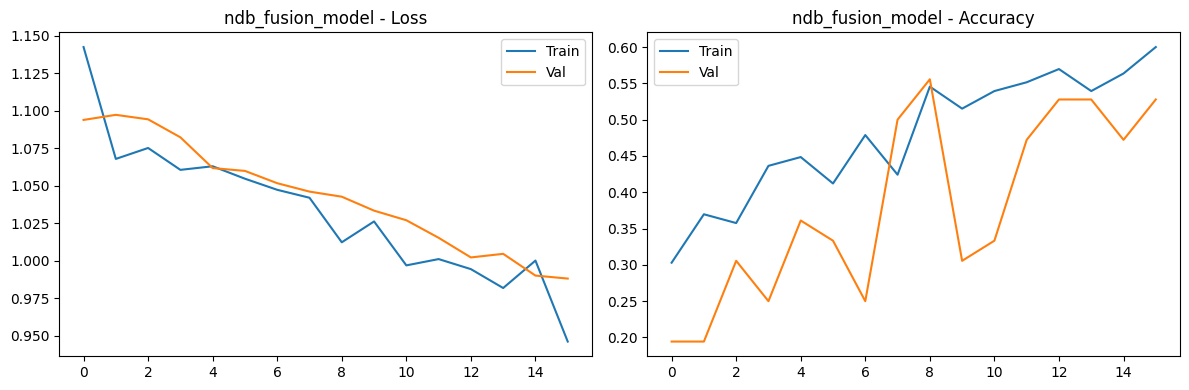

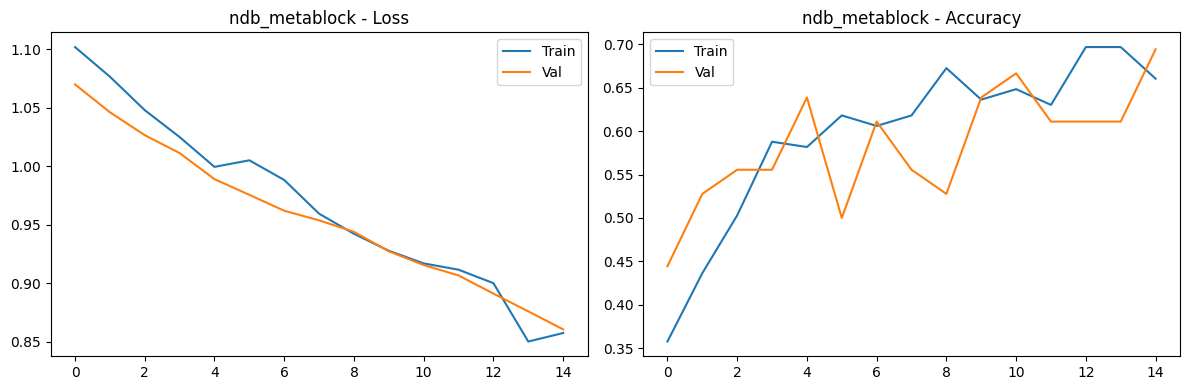

In [37]:
plot_curves(
    [1.1426,1.0680,1.0753,1.0607,1.0631,1.0548,1.0474,1.0421,1.0124,1.0263,0.9970,1.0012,0.9945,0.9819,1.0002,0.9462],
    [1.0940,1.0974,1.0944,1.0824,1.0619,1.0600,1.0518,1.0462,1.0428,1.0335,1.0271,1.0154,1.0023,1.0047,0.9902,0.9882],
    [0.3030,0.3697,0.3576,0.4364,0.4485,0.4121,0.4788,0.4242,0.5455,0.5152,0.5394,0.5515,0.5697,0.5394,0.5636,0.6000],
    [0.1944,0.1944,0.3056,0.2500,0.3611,0.3333,0.2500,0.5000,0.5556,0.3056,0.3333,0.4722,0.5278,0.5278,0.4722,0.5278],
    'ndb_fusion_model')

plot_curves(
    [1.1019,1.0766,1.0480,1.0250,0.9995,1.0051,0.9883,0.9595,0.9423,0.9278,0.9170,0.9116,0.9001,0.8502,0.8575],
    [1.0700,1.0462,1.0266,1.0113,0.9890,0.9756,0.9620,0.9538,0.9440,0.9273,0.9156,0.9067,0.8912,0.8760,0.8606],
    [0.3576,0.4364,0.5030,0.5879,0.5818,0.6182,0.6061,0.6182,0.6727,0.6364,0.6485,0.6303,0.6970,0.6970,0.6606],
    [0.4444,0.5278,0.5556,0.5556,0.6389,0.5000,0.6111,0.5556,0.5278,0.6389,0.6667,0.6111,0.6111,0.6111,0.6944],
    'ndb_metablock')

In [38]:
class ImageOnlyModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer4' not in name:
                param.requires_grad = False
        self.classifier = nn.Sequential(
            nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes)
        )
    def forward(self, image, meta=None):
        feat = self.image_branch(image).flatten(1)
        return self.classifier(feat)

class MetaOnlyModel(nn.Module):
    def __init__(self, meta_input_dim, num_classes):
        super().__init__()
        self.meta_branch = nn.Sequential(
            nn.Linear(meta_input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU()
        )
        self.classifier = nn.Sequential(
            nn.Linear(32, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, num_classes)
        )
    def forward(self, image, meta):
        feat = self.meta_branch(meta)
        return self.classifier(feat)

In [39]:
img_model_ndb = ImageOnlyModel(num_classes=3).to(device)
img_optimizer_ndb = torch.optim.Adam(filter(lambda p: p.requires_grad, img_model_ndb.parameters()), lr=1e-4, weight_decay=1e-4)

best_val_acc = 0
for epoch in range(10):
    train_loss, train_acc = train_one_epoch(img_model_ndb, train_loader_ndb, criterion_ndb, img_optimizer_ndb, device)
    val_loss, val_acc = evaluate(img_model_ndb, val_loader_ndb, criterion_ndb, device)
    print(f"Epoch {epoch+1}/10 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(img_model_ndb.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_image_only_ndb.pth')
        print("  -> Saved new best model")

Epoch 1/10 - Train loss: 1.1292, Train acc: 0.2727 - Val loss: 1.0747, Val acc: 0.2500
  -> Saved new best model
Epoch 2/10 - Train loss: 1.1010, Train acc: 0.3091 - Val loss: 1.0741, Val acc: 0.3889
  -> Saved new best model
Epoch 3/10 - Train loss: 1.0807, Train acc: 0.4061 - Val loss: 1.0622, Val acc: 0.3611
Epoch 4/10 - Train loss: 1.0877, Train acc: 0.4182 - Val loss: 1.0688, Val acc: 0.3611
Epoch 5/10 - Train loss: 1.0759, Train acc: 0.4303 - Val loss: 1.0490, Val acc: 0.4722
  -> Saved new best model
Epoch 6/10 - Train loss: 1.0654, Train acc: 0.4788 - Val loss: 1.0381, Val acc: 0.4722
Epoch 7/10 - Train loss: 1.0686, Train acc: 0.4364 - Val loss: 1.0376, Val acc: 0.4167
Epoch 8/10 - Train loss: 1.0379, Train acc: 0.5515 - Val loss: 1.0423, Val acc: 0.3056
Epoch 9/10 - Train loss: 1.0378, Train acc: 0.5152 - Val loss: 1.0375, Val acc: 0.3333
Epoch 10/10 - Train loss: 1.0414, Train acc: 0.5273 - Val loss: 1.0399, Val acc: 0.4167


In [40]:
img_model_ndb.load_state_dict(torch.load('/content/drive/MyDrive/skin-cancer-fusion/best_image_only_ndb.pth'))
test_loss, test_acc = evaluate(img_model_ndb, test_loader_ndb, criterion_ndb, device)
print(f"NDB Image-only Test acc: {test_acc:.4f}")

NDB Image-only Test acc: 0.2500


In [41]:
meta_model_ndb = MetaOnlyModel(meta_input_dim=25, num_classes=3).to(device)
meta_optimizer_ndb = torch.optim.Adam(meta_model_ndb.parameters(), lr=1e-4, weight_decay=1e-4)

best_val_acc = 0
for epoch in range(10):
    train_loss, train_acc = train_one_epoch(meta_model_ndb, train_loader_ndb, criterion_ndb, meta_optimizer_ndb, device)
    val_loss, val_acc = evaluate(meta_model_ndb, val_loader_ndb, criterion_ndb, device)
    print(f"Epoch {epoch+1}/10 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(meta_model_ndb.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_meta_only_ndb.pth')
        print("  -> Saved new best model")

Epoch 1/10 - Train loss: 1.0989, Train acc: 0.2424 - Val loss: 1.0989, Val acc: 0.2500
  -> Saved new best model
Epoch 2/10 - Train loss: 1.1002, Train acc: 0.2424 - Val loss: 1.0984, Val acc: 0.2500
Epoch 3/10 - Train loss: 1.1001, Train acc: 0.2424 - Val loss: 1.0980, Val acc: 0.2500
Epoch 4/10 - Train loss: 1.0973, Train acc: 0.2424 - Val loss: 1.0976, Val acc: 0.2500
Epoch 5/10 - Train loss: 1.0951, Train acc: 0.2424 - Val loss: 1.0971, Val acc: 0.2500
Epoch 6/10 - Train loss: 1.0975, Train acc: 0.2424 - Val loss: 1.0967, Val acc: 0.2500
Epoch 7/10 - Train loss: 1.0968, Train acc: 0.2485 - Val loss: 1.0962, Val acc: 0.2500
Epoch 8/10 - Train loss: 1.0989, Train acc: 0.2424 - Val loss: 1.0955, Val acc: 0.2500
Epoch 9/10 - Train loss: 1.0966, Train acc: 0.2424 - Val loss: 1.0948, Val acc: 0.2500
Epoch 10/10 - Train loss: 1.0912, Train acc: 0.2424 - Val loss: 1.0940, Val acc: 0.2500


In [42]:
meta_model_ndb.load_state_dict(torch.load('/content/drive/MyDrive/skin-cancer-fusion/best_meta_only_ndb.pth'))
test_loss, test_acc = evaluate(meta_model_ndb, test_loader_ndb, criterion_ndb, device)
print(f"NDB Meta-only Test acc: {test_acc:.4f}")

NDB Meta-only Test acc: 0.2222


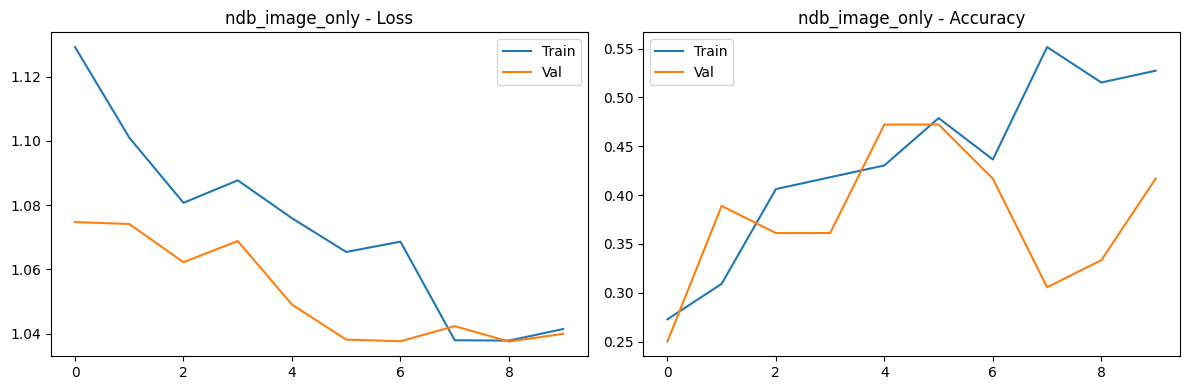

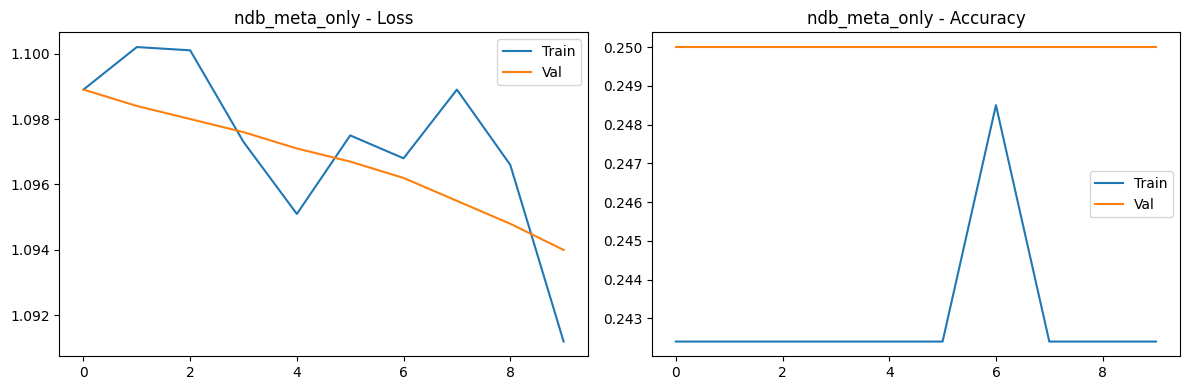

In [43]:
plot_curves(
    [1.1292,1.1010,1.0807,1.0877,1.0759,1.0654,1.0686,1.0379,1.0378,1.0414],
    [1.0747,1.0741,1.0622,1.0688,1.0490,1.0381,1.0376,1.0423,1.0375,1.0399],
    [0.2727,0.3091,0.4061,0.4182,0.4303,0.4788,0.4364,0.5515,0.5152,0.5273],
    [0.2500,0.3889,0.3611,0.3611,0.4722,0.4722,0.4167,0.3056,0.3333,0.4167],
    'ndb_image_only')

plot_curves(
    [1.0989,1.1002,1.1001,1.0973,1.0951,1.0975,1.0968,1.0989,1.0966,1.0912],
    [1.0989,1.0984,1.0980,1.0976,1.0971,1.0967,1.0962,1.0955,1.0948,1.0940],
    [0.2424,0.2424,0.2424,0.2424,0.2424,0.2424,0.2485,0.2424,0.2424,0.2424],
    [0.2500,0.2500,0.2500,0.2500,0.2500,0.2500,0.2500,0.2500,0.2500,0.2500],
    'ndb_meta_only')